In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

np.random.seed(42)
sns.set_style("whitegrid")

<h1>Scenario A</h1>

App Review Analysis: A product team analyzes their app's reviews on the App Store to understand user satisfaction. The average rating is 4.3/5, so they conclude that most users are happy. They plan to reduce investment in customer support.

<pre>
Answer: 
Selection
As most of the unsatisfied customers don't have reviews for the app and the reviews are mostly from the satisfied customers the rating is higher than expected. 
The best way to solve the problem is to collect more representative data by gathering feedback from a broader set of users and analyze this data(both visually and by metrics)
</pre> 

<h1>Scenario B</h1>

Startup Success Study: A business school studies 200 successful tech startups (all founded in the last 10 years and still operating) to identify common traits that predict startup success. They find that 80% had a pivot in their first two years and conclude that pivoting is a key success strategy.

<pre>
Answer:
Survivorship bias
As the analysis is only based on the succesful startups there's a huge possibility of mistaken outcome than normal. 200 succesful startups might be a very small sample of whole population which don't contain much information reflecting the population.
The best way to solve this problem is to include both successful and failed startups and compare the frequency of pivoting across these groups to determine whether it is actually associated with success.
</pre>

<h1>Scenario C</h1>

Health Survey: A health organization sends a voluntary online survey to 50,000 email subscribers asking about exercise habits and health outcomes. The survey receives 5,000 responses (10% response rate). Results show that respondents exercise an average of 5 hours per week and have excellent self-reported health.

<pre>
Answer: 
Non-response bias
Only 10% of the surveyed individuals responded. Those who chose to respond are likely more health-conscious and engaged, which makes them unrepresentative of the full population.
The organization should aim to increase the response rate or adjust for non-response by using follow-ups or weighting techniques to better reflect the entire population.
</pre>

<h1>Scenario D</h1>

Salary Benchmarking: A recruiting platform publishes average salaries by job title based on user-submitted salary data. The platform is popular among tech workers in large cities. A company in a small town uses this data to set their salary bands.

<pre>
Answer:
Selection bias
The salary data is collected from a platform that is primarily used by tech workers in large cities. As a result, the sample is not representative of the broader job market, particularly for a company located in a small town.
The company should use more representative data sources, such as local salary surveys or industry benchmarks that reflect similar geographic and economic conditions.
</pre>

In [127]:
N = 100000
population = {'age' : np.random.normal(40, 15, size=N).clip(18, 85)}
population['income'] = (population['age']*1500 + np.random.normal(0,20000,N)).clip(15000,250000)


satisfaction = np.zeros(N)

high_income = population['income'] > 45000

satisfaction[high_income] = np.random.randint(6, 11, size=high_income.sum())
satisfaction[~high_income] = np.random.randint(0, 6, size=(~high_income).sum())

population['satisfaction'] = satisfaction

population['region'] = np.random.choice(['Urban', 'Suburban', 'Rural'], p = [0.60,0.25,0.15], size=N)

In [128]:
population = pd.DataFrame(population)
population

,age,income,satisfaction,region
0,47.450712,91787.960203,10.0,Suburban
1,37.926035,33781.957883,0.0,Urban
2,49.715328,86081.735912,8.0,Urban
3,62.845448,81883.402606,10.0,Rural
4,36.487699,48183.492941,10.0,Urban
...,...,...,...,...
99995,36.621626,29641.473722,4.0,Rural
99996,31.453337,58493.088466,9.0,Urban
99997,46.137776,72407.063537,7.0,Suburban
99998,36.833625,72363.899145,7.0,Rural


In [129]:
print('True population parameters:')
print(population.describe())
print(population['region'].value_counts(normalize=True)*100)

True population parameters:
                 age         income  satisfaction
count  100000.000000  100000.000000  100000.00000
mean       40.483464   61342.346479       6.34986
std        14.076637   27999.444060       2.94253
min        18.000000   15000.000000       0.00000
25%        29.882592   40460.653743       4.00000
50%        40.039744   60267.558826       7.00000
75%        50.153720   80404.994106       9.00000
max        85.000000  181514.505521      10.00000
region
Urban       59.976
Suburban    25.208
Rural       14.816
Name: proportion, dtype: float64


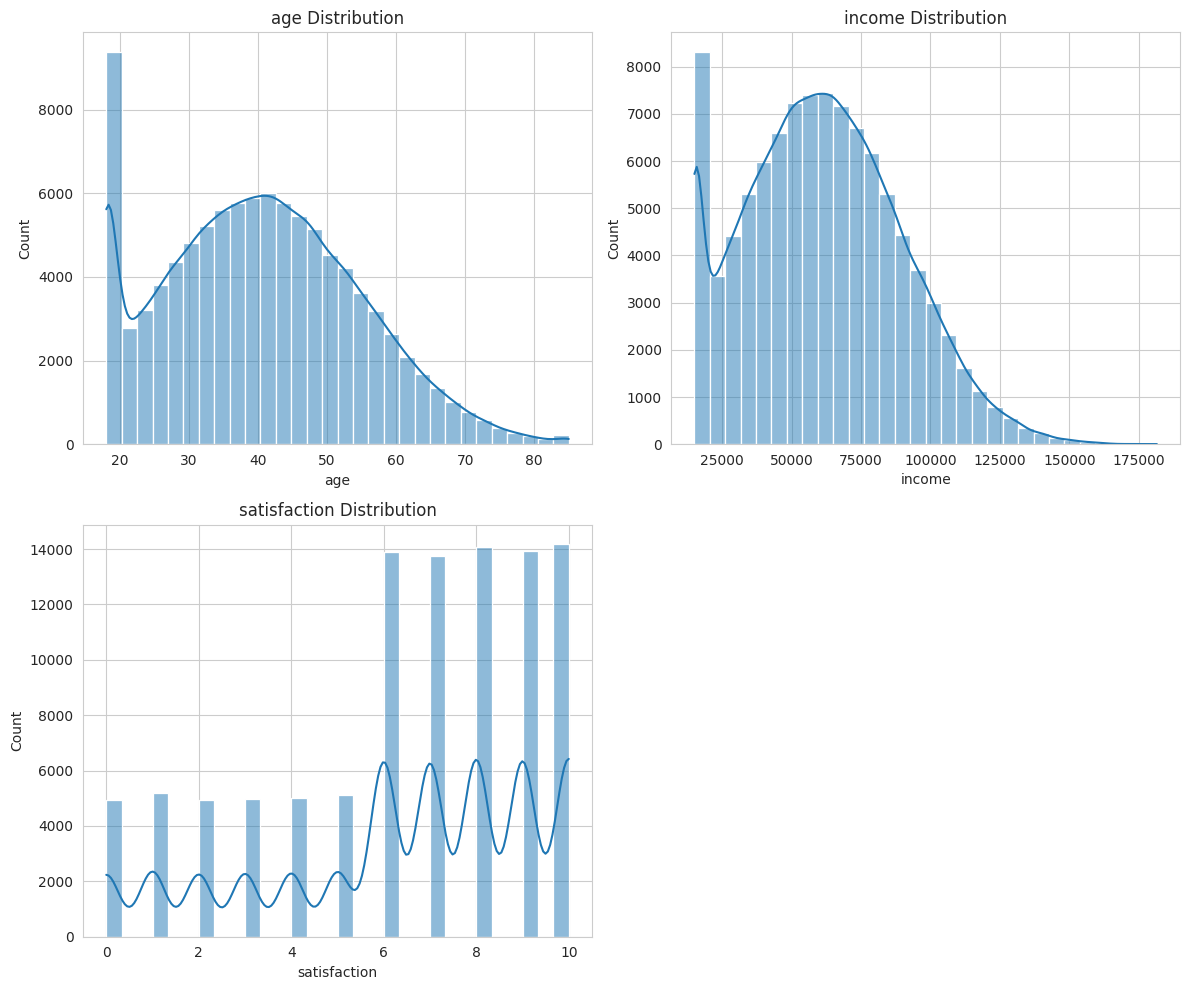

In [130]:
numerical_cols = population.select_dtypes(include='number').columns
num_vars = len(numerical_cols)

n_cols = 2
n_rows = int(np.ceil(num_vars / n_cols))

plt.figure(figsize=(12, 5 * n_rows))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(population[col], bins=30, kde=True)
    plt.title(f'{col} Distribution')

plt.tight_layout()
plt.show()



In [131]:
print(population.describe()) 
print(population['region'].value_counts(normalize=True)*100)

                 age         income  satisfaction
count  100000.000000  100000.000000  100000.00000
mean       40.483464   61342.346479       6.34986
std        14.076637   27999.444060       2.94253
min        18.000000   15000.000000       0.00000
25%        29.882592   40460.653743       4.00000
50%        40.039744   60267.558826       7.00000
75%        50.153720   80404.994106       9.00000
max        85.000000  181514.505521      10.00000
region
Urban       59.976
Suburban    25.208
Rural       14.816
Name: proportion, dtype: float64


In [132]:
#Simple random sampling
sample_size = 200
sample = population.sample(sample_size, random_state=42)
print(sample.describe())
print(sample['region'].value_counts(normalize=True)*100)

              age         income  satisfaction
count  200.000000     200.000000    200.000000
mean    40.717925   63019.542075      6.590000
std     13.964540   28991.015488      2.905877
min     18.000000   15000.000000      0.000000
25%     29.704831   41562.170115      5.000000
50%     40.760956   63271.873311      7.000000
75%     49.556969   81288.245794      9.000000
max     78.004177  152503.904982     10.000000
region
Urban       62.0
Suburban    21.0
Rural       17.0
Name: proportion, dtype: float64


In [133]:
#Biased sample - only urban customers
biased_sample = population[population['region'] == 'Urban'].sample(sample_size, random_state=42)
print(biased_sample.describe())
biased_sample['region'].value_counts(normalize=True)*100

              age         income  satisfaction
count  200.000000     200.000000    200.000000
mean    42.078518   62973.496913      6.565000
std     15.011883   30540.347107      2.952858
min     18.000000   15000.000000      0.000000
25%     29.789848   43250.732616      4.750000
50%     41.882823   62685.763906      7.000000
75%     51.820036   81673.171297      9.000000
max     79.568226  180875.903446     10.000000


region
Urban    100.0
Name: proportion, dtype: float64

In [134]:
#Biased sampling - High income customers
high_income_sample = population[population['income'] > population['income'].median()].sample(sample_size, random_state=42)
print(high_income_sample.describe())
high_income_sample['region'].value_counts(normalize=True)*100

              age         income  satisfaction
count  200.000000     200.000000    200.000000
mean    47.979924   83798.992235      8.110000
std     11.527225   19116.129254      1.377457
min     18.000000   60481.466519      6.000000
25%     40.130139   68121.371411      7.000000
50%     48.349738   79429.993558      8.000000
75%     55.584124   96273.903040      9.000000
max     73.932302  149672.657692     10.000000


region
Urban       60.5
Suburban    25.0
Rural       14.5
Name: proportion, dtype: float64

In [135]:
# Create comparison table
comparison = pd.DataFrame({
    'Population': population[['age','income','satisfaction']].mean(),
    'Simple Random Sample': sample[['age','income','satisfaction']].mean(),
    'Urban Sample': biased_sample[['age','income','satisfaction']].mean(),
    'High-Income Sample': high_income_sample[['age','income','satisfaction']].mean()
})

comparison


,Population,Simple Random Sample,Urban Sample,High-Income Sample
age,40.483464,40.717925,42.078518,47.979924
income,61342.346479,63019.542075,62973.496913,83798.992235
satisfaction,6.349860,6.590000,6.565000,8.110000


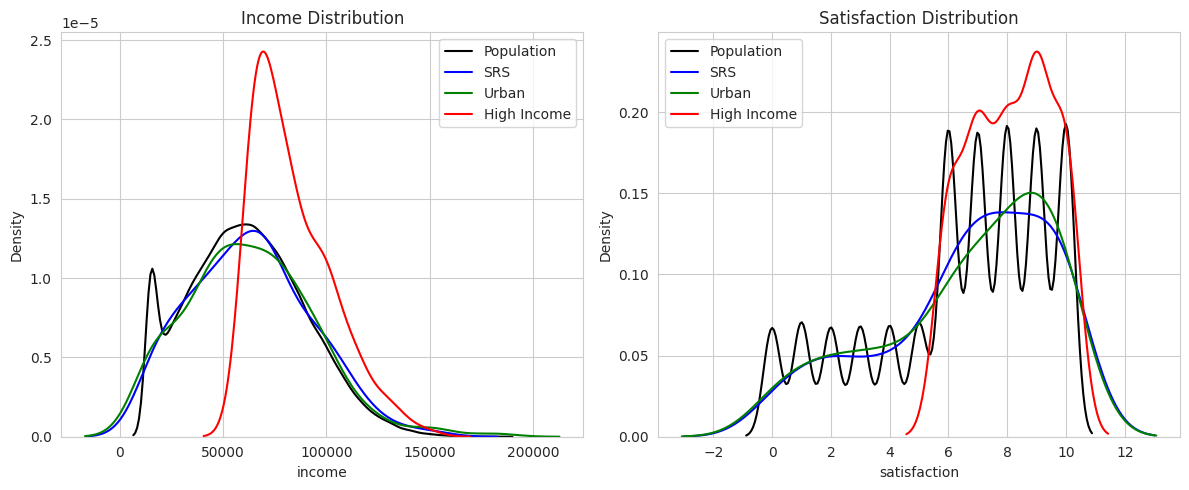

In [136]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.kdeplot(population['income'], label='Population', color='black')
sns.kdeplot(sample['income'], label='SRS', color='blue')
sns.kdeplot(biased_sample['income'], label='Urban', color='green')
sns.kdeplot(high_income_sample['income'], label='High Income', color='red')
plt.title('Income Distribution')
plt.legend()

plt.subplot(1,2,2)
sns.kdeplot(population['satisfaction'], label='Population', color='black')
sns.kdeplot(sample['satisfaction'], label='SRS', color='blue')
sns.kdeplot(biased_sample['satisfaction'], label='Urban', color='green')
sns.kdeplot(high_income_sample['satisfaction'], label='High Income', color='red')
plt.title('Satisfaction Distribution')
plt.legend()

plt.tight_layout()
plt.show()

